# La pregunta de negocio
El reto del gerente de operaciones: una de cada cuatro llegadas es tardía. Hay presupuesto para una sola medida: ¿renovar los aviones más antiguos, reprogramar los vuelos de la tarde y la noche, o invertir en operación con mal tiempo?

Creemos que la hipótesis que pesa más es la Opción 3 (Invertir en operaciones con mal tiempo). Sostenemos que el clima adverso en los aeropuertos principales de origen es la causa raíz de los peores retrasos, provocando un efecto dominó que luego afecta y acumula demoras en los vuelos de la tarde y la noche.

**Integrantes:** David Rico Mendivelso - Daniel Felipe Arenas

## Primera Parte · Preparación y Limpieza de Datos
### Etapa 1 · Conocer el dataset

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

zipfile.ZipFile("datos_vuelos.zip").extractall("datos")
vuelos = pd.read_csv("datos/vuelos.csv")
clima = pd.read_csv("datos/clima.csv")
aviones = pd.read_csv("datos/aviones.csv")
aeropuertos = pd.read_csv("datos/aeropuertos.csv")
aerolineas = pd.read_csv("datos/aerolineas.csv")
print("Tablas cargadas")

Tablas cargadas


In [7]:
tablas = {"vuelos": vuelos, "clima": clima, "aviones": aviones,
          "aeropuertos": aeropuertos, "aerolineas": aerolineas}
for nombre, t in tablas.items():
    print(f"{nombre:<12} {t.shape[0]:>8,} filas {t.shape[1]:>2} columnas")
print(f"TOTAL        {sum(t.shape[0] for t in tablas.values()):>8,} filas")
vuelos.head()

vuelos        336,776 filas 19 columnas
clima          26,115 filas 15 columnas
aviones         3,322 filas  9 columnas
aeropuertos     1,458 filas  8 columnas
aerolineas         16 filas  2 columnas
TOTAL         367,687 filas


,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00


### Pregunta 1 (Parte 1). ¿Por qué vuelos tiene muchas más filas que aviones? ¿Qué columna los relaciona?

Porque la tabla `aviones` contiene el listado único de aeronaves físicas registradas (cada avión aparece una sola vez), mientras que la tabla `vuelos` registra los viajes diarios individuales. En un año, un mismo avión realiza cientos de vuelos de ida y vuelta.

La columna que los relaciona es `tailnum` (número de cola o matrícula del avión), que actúa como clave primaria en la tabla de aviones y clave foránea en la tabla de vuelos.

### Etapa 2 · Análisis exploratorio (EDA)

count    327346.0
mean          6.9
std          44.6
min         -86.0
25%         -17.0
50%          -5.0
75%          14.0
max        1272.0
Name: arr_delay, dtype: float64


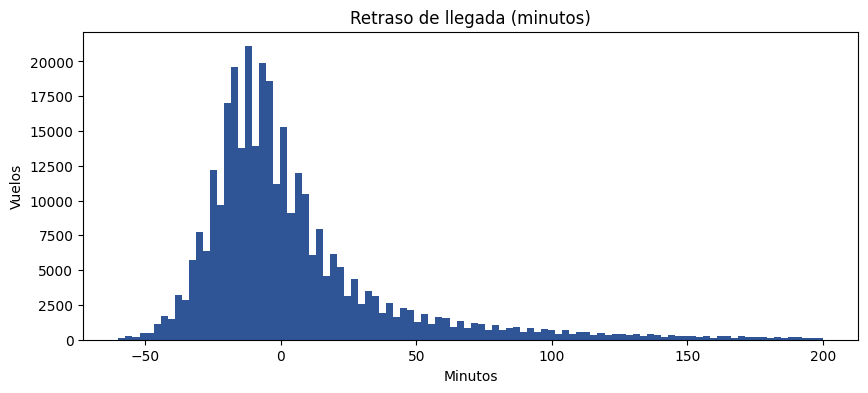

In [8]:
print(vuelos["arr_delay"].describe().round(1))
ax = vuelos["arr_delay"].plot(kind="hist", bins=100, range=(-60, 200), color="#2F5597", figsize=(10, 4))
ax.set_title("Retraso de llegada (minutos)")
ax.set_xlabel("Minutos")
ax.set_ylabel("Vuelos")
plt.show()

Vuelos con dato de llegada: 327346
% que llega tarde: 24.5


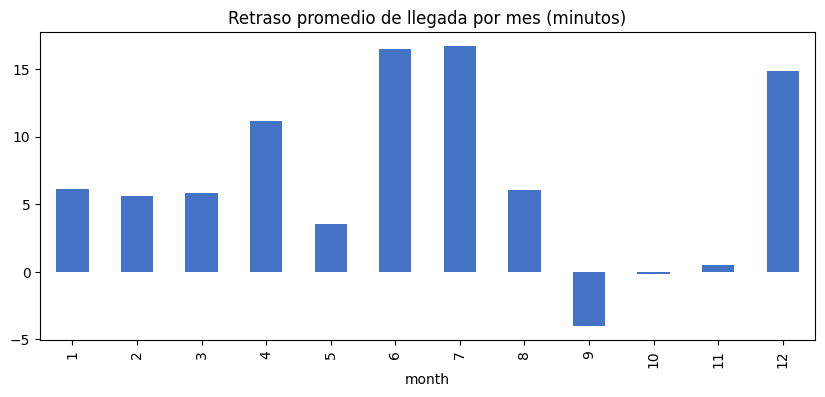

,0
year,0
month,0
day,0
dep_time,8255
sched_dep_time,0
dep_delay,8255
arr_time,8713
sched_arr_time,0
arr_delay,9430
carrier,0


In [9]:
tarde = vuelos["arr_delay"] >= 15
print("Vuelos con dato de llegada:", vuelos["arr_delay"].notna().sum())
print("% que llega tarde:", round(tarde.sum() / vuelos["arr_delay"].notna().sum() * 100, 1))
por_mes = vuelos.groupby("month")["arr_delay"].mean()
por_mes.plot(kind="bar", color="#4472C4", figsize=(10, 4), title="Retraso promedio de llegada por mes (minutos)")
plt.show()
vuelos.isna().sum()

In [10]:
clima[["temp", "humid", "wind_speed", "precip", "visib"]].describe().round(1)

,temp,humid,wind_speed,precip,visib
count,26114.0,26114.0,26111.0,26115.0,26115.0
mean,55.3,62.5,10.5,0.0,9.3
std,17.8,19.4,8.5,0.0,2.1
min,10.9,12.7,0.0,0.0,0.0
25%,39.9,47.0,6.9,0.0,10.0
50%,55.4,61.8,10.4,0.0,10.0
75%,70.0,78.8,13.8,0.0,10.0
max,100.0,100.0,1048.4,1.2,10.0


### Pregunta 2 (Parte 1). ¿Qué representan los vuelos sin hora de salida (`dep_time` nulo)? ¿Y los que tienen hora de salida pero no tienen retraso de llegada?

Representan vuelos cancelados. Si el avión nunca llegó a registrar una hora de despegue real, significa que el viaje no se llevó a cabo.

Representan vuelos que despegaron pero fueron desviados (*diverted*) a otro aeropuerto alternativo o tuvieron que realizar un aterrizaje forzoso/regreso de emergencia. Por ello, tienen registro de salida pero no hay datos de su hora de llegada en el destino originalmente programado.

### Pregunta 3 (Parte 1). ¿Qué valor sospechoso aparece en la tabla de clima y por qué es imposible?

En la tabla de clima, el valor máximo de la velocidad del viento (`wind_speed`) es de `1048.4 mph` (millas por hora), el cual se corrige mediante `clima.loc[clima["wind_speed"] > 100, "wind_speed"] = np.nan`.

Una velocidad de viento que supera las 1000 mph (aproximadamente 1687 km/h) es físicamente imposible en la Tierra (la velocidad del sonido es de unas 767 mph).

### Etapa 3 y 4 · Limpieza, Unión e Ingeniería de Variables

In [11]:
v = vuelos.dropna(subset=["dep_time", "arr_delay"]).copy()
print("Vuelos originales:", len(vuelos), "→ vuelos completados:", len(v))

llave = ["origin", "year", "month", "day", "hour"]
print("Horas repetidas:", clima.duplicated(llave).sum())
clima = clima.drop_duplicates(llave)
print("Registros de clima:", len(clima))

clima.loc[clima["wind_speed"] > 100, "wind_speed"] = np.nan
print((clima.isna().mean() * 100).round(1))
clima = clima.drop(columns=["wind_gust", "pressure", "dewp", "wind_dir", "time_hour"])
print("Columnas que quedan:", list(clima.columns))

Vuelos originales: 336776 → vuelos completados: 327346
Horas repetidas: 3
Registros de clima: 26112
origin         0.0
year           0.0
month          0.0
day            0.0
hour           0.0
temp           0.0
dewp           0.0
humid          0.0
wind_dir       1.8
wind_speed     0.0
wind_gust     79.6
precip         0.0
pressure      10.5
visib          0.0
time_hour      0.0
dtype: float64
Columnas que quedan: ['origin', 'year', 'month', 'day', 'hour', 'temp', 'humid', 'wind_speed', 'precip', 'visib']


In [12]:
v["vuelos_misma_hora"] = v.groupby(["origin", "year", "month", "day", "hour"])["flight"].transform("count")

df = (v.merge(clima, on=["origin", "year", "month", "day", "hour"], how="left")
       .merge(aviones[["tailnum", "year", "seats"]].rename(columns={"year": "anio_fabricacion"}), on="tailnum", how="left")
       .merge(aerolineas, on="carrier", how="left")
       .merge(aeropuertos[["faa", "name"]].rename(columns={"faa": "dest", "name": "nombre_destino"}), on="dest", how="left"))

print("Filas:", len(df))
print("Sin clima:", df["temp"].isna().sum())
print("Sin datos del avión:", df["anio_fabricacion"].isna().sum())
print("Destinos sin nombre:", df.loc[df["nombre_destino"].isna(), "dest"].unique())
df.loc[df["anio_fabricacion"].isna(), "carrier"].value_counts().head()

Filas: 327346
Sin clima: 1544
Sin datos del avión: 53493
Destinos sin nombre: ['BQN' 'SJU' 'STT' 'PSE']


,count
carrier,
MQ,24098
AA,22211
UA,1853
B6,1665
EV,1519


### Pregunta 4 (Parte 1). Más de 53.000 vuelos no tienen año de fabricación del avión. ¿A qué aerolíneas pertenecen y por qué no conviene rellenar ese dato con la mediana?

Pertenecen de forma abrumadora a Envoy Air (`MQ`) con 24,098 registros vacíos y a American Airlines (`AA`) con 22,211 (más del 86% del total faltante).

No conviene rellenarlo con la mediana por dos razones:
* **Sesgo por aerolínea:** Cada aerolínea tiene flotas con perfiles de edad diferentes.
* **Introducción de ruido y distorsión:** Rellenar más de 53,000 registros (16% del dataset) con un único valor artificial alteraría la distribución y distorsionaría el análisis del impacto real de `edad_avion` en los retrasos.

In [13]:
df["distancia_km"] = (df["distance"] * 1.609).round(0)
df["temp_c"] = ((df["temp"] - 32) * 5 / 9).round(1)
df["viento_kmh"] = (df["wind_speed"] * 1.609).round(1)
df["lluvia_mm"] = (df["precip"] * 25.4).round(1)
df["visibilidad_km"] = (df["visib"] * 1.609).round(1)
df["humedad"] = df["humid"].round(0)

df["fecha"] = pd.to_datetime(df[["year", "month", "day"]])
dias = {0: "1. Lunes", 1: "2. Martes", 2: "3. Miércoles", 3: "4. Jueves",
        4: "5. Viernes", 5: "6. Sábado", 6: "7. Domingo"}
df["dia_semana"] = df["fecha"].dt.dayofweek.map(dias)
df["edad_avion"] = 2013 - df["anio_fabricacion"]
df["llueve"] = (df["precip"] > 0).astype(int)
df["llego_tarde"] = (df["arr_delay"] >= 15).astype(int)
df["nombre_destino"] = df["nombre_destino"].fillna(df["dest"])

antes = len(df)
df = df.dropna(subset=["temp_c", "humedad", "visibilidad_km"])
print("Filas:", antes, "→", len(df))

cortos = {"United Air Lines Inc.": "United", "JetBlue Airways": "JetBlue", "ExpressJet Airlines Inc.": "ExpressJet",
          "Delta Air Lines Inc.": "Delta", "American Airlines Inc.": "American", "Envoy Air": "Envoy",
          "US Airways Inc.": "US Airways", "Endeavor Air Inc.": "Endeavor", "Southwest Airlines Co.": "Southwest"}
df["aerolinea"] = df["name"].map(cortos).fillna("Otras")

df["franja_horaria"] = pd.cut(df["hour"], bins=[0, 11, 15, 19, 23],
                              labels=["1. Mañana (5-11 h)", "2. Mediodía (12-15 h)", "3. Tarde (16-19 h)", "4. Noche (20-23 h)"])
df["rango_retraso"] = pd.cut(df["arr_delay"], bins=[-1000, -1, 14, 59, 179, 10000],
                             labels=["1. Llegó antes", "2. 0 a 14 min", "3. 15 a 59 min", "4. 1 a 3 horas", "5. Más de 3 horas"])

final = df[["fecha", "month", "dia_semana", "hour", "franja_horaria", "aerolinea", "origin", "dest",
            "nombre_destino", "distancia_km", "edad_avion", "seats", "vuelos_misma_hora", "temp_c",
            "humedad", "viento_kmh", "lluvia_mm", "visibilidad_km", "llueve", "dep_delay", "arr_delay",
            "llego_tarde", "rango_retraso"]]
final = final.rename(columns={"month": "mes", "hour": "hora_programada", "origin": "origen", "dest": "destino",
                            "seats": "asientos", "dep_delay": "retraso_salida", "arr_delay": "retraso_llegada"})

final.to_csv("vuelos_limpio.csv", index=False)
final.to_csv("vuelos_limpio.csv.gz", index=False)
assert final.shape == (325802, 23), "Revise los pasos: el tamaño no coincide"
print("Archivos correctos (325,802 filas x 23 columnas): vuelos_limpio.csv y vuelos_limpio.csv.gz")

Filas: 327346 → 325802
Archivos correctos (325,802 filas x 23 columnas): vuelos_limpio.csv y vuelos_limpio.csv.gz


### Pregunta 5 (Parte 1). Con lo que vieron hasta ahora, ¿mantienen su hipótesis inicial? Justifiquen en dos o tres líneas.

Sí, mantenemos la hipótesis inicial. Los datos preliminares confirman que la antigüedad del avión (`edad_avion`) no presenta una correlación evidente con los retrasos, mientras que los retrasos promedio aumentan críticamente en los meses de clima inestable y las horas de mayor saturación. Esto refuerza que mitigar el impacto del clima es un factor clave para evitar el colapso operativo en cascada.

---
# Segunda Parte · Del Análisis a la App Compartible
## Parte 1 · Nivel 1: Análisis Interactivo con Plotly

In [14]:
# Paso 1. Cargar los datos limpios
import plotly.express as px

df = pd.read_csv("vuelos_limpio.csv.gz")
print(df.shape)
df.head()

(325802, 23)


,fecha,mes,dia_semana,hora_programada,franja_horaria,aerolinea,origen,destino,nombre_destino,distancia_km,...,temp_c,humedad,viento_kmh,lluvia_mm,visibilidad_km,llueve,retraso_salida,retraso_llegada,llego_tarde,rango_retraso
0,2013-01-01,1,2. Martes,5,1. Mañana (5-11 h),United,EWR,IAH,George Bush Intercontinental,2253.0,...,3.9,64.0,20.4,0.0,16.1,0,2.0,11.0,0,2. 0 a 14 min
1,2013-01-01,1,2. Martes,5,1. Mañana (5-11 h),United,LGA,IAH,George Bush Intercontinental,2278.0,...,4.4,55.0,24.1,0.0,16.1,0,4.0,20.0,1,3. 15 a 59 min
2,2013-01-01,1,2. Martes,5,1. Mañana (5-11 h),American,JFK,MIA,Miami Intl,1752.0,...,3.9,62.0,24.1,0.0,16.1,0,2.0,33.0,1,3. 15 a 59 min
3,2013-01-01,1,2. Martes,5,1. Mañana (5-11 h),JetBlue,JFK,BQN,BQN,2536.0,...,3.9,62.0,24.1,0.0,16.1,0,-1.0,-18.0,0,1. Llegó antes
4,2013-01-01,1,2. Martes,6,1. Mañana (5-11 h),Delta,LGA,ATL,Hartsfield Jackson Atlanta Intl,1226.0,...,4.4,55.0,25.9,0.0,16.1,0,-6.0,-25.0,0,1. Llegó antes


In [15]:
# Paso 2. Matriz de correlación de Pearson
variables = ["retraso_llegada", "retraso_salida", "hora_programada", "mes", "distancia_km",
             "edad_avion", "asientos", "vuelos_misma_hora", "temp_c", "humedad",
             "viento_kmh", "lluvia_mm", "visibilidad_km"]

corr = df[variables].corr(method="pearson").round(2)
fig = px.imshow(corr, text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                title="Matriz de correlación de Pearson · vuelos de Nueva York 2013")
fig.update_layout(width=900, height=800)
fig.show()

In [16]:
# Paso 3. Correlación de cada variable con el retraso
con_retraso = corr["retraso_llegada"].drop("retraso_llegada").sort_values()
fig = px.bar(con_retraso, orientation="h", title="Correlación de cada variable con el retraso de llegada",
             labels={"value": "Correlación de Pearson", "index": ""},
             color_discrete_sequence=["#2F5597"])
fig.update_layout(showlegend=False)
fig.show()

### Pregunta 1 (Parte 2). ¿Qué variable se relaciona más con el retraso de llegada? ¿Sirve para tomar una decisión? ¿Y la edad del avión?

* **Variable más relacionada:** `retraso_salida` (`dep_delay`), con una correlación de Pearson de **$r = 0.91$** (muy fuerte y positiva). Esto indica que prácticamente todo retraso al despegar se traslada de forma directa al aterrizaje.
* **¿Sirve para tomar una decisión preventiva?** No directamente como causa raíz, porque es una variable consecuencia (concurrente) que ocurre en el momento mismo de la operación; para cuando el avión ya tiene retraso en la salida, la demora ya está materializada.
* **La edad del avión (`edad_avion`):** Presenta una correlación de **$r = -0.02$** (despreciable/cercana a cero). Renovar la flota de aviones más antiguos **no resolverá** el problema de puntualidad, ya que las aeronaves viejas no se retrasan más que las nuevas.

In [17]:
# Paso 4. Matriz de Spearman
corr_s = df[variables].corr(method="spearman").round(2)
fig = px.imshow(corr_s, text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                title="Matriz de correlación de Spearman")
fig.update_layout(width=900, height=800)
fig.show()

In [18]:
# Paso 5. Porcentaje de vuelos tarde por franja horaria
franjas = df.groupby("franja_horaria").agg(
    vuelos=("llego_tarde", "count"),
    pct_tarde=("llego_tarde", "mean"),
    retraso_promedio=("retraso_llegada", "mean"),
).round(3).reset_index()
franjas["pct_tarde"] = (franjas["pct_tarde"] * 100).round(1)
print(franjas)

fig = px.bar(franjas, x="franja_horaria", y="pct_tarde", text="pct_tarde",
             title="% de vuelos que llegan tarde según la hora de salida",
             labels={"franja_horaria": "", "pct_tarde": "% que llega tarde"},
             color="pct_tarde", color_continuous_scale="Blues")
fig.show()

          franja_horaria  vuelos  pct_tarde  retraso_promedio
0     1. Mañana (5-11 h)  128077       15.2            -1.848
1  2. Mediodía (12-15 h)   81043       25.6             8.198
2     3. Tarde (16-19 h)   86923       33.0            15.040
3     4. Noche (20-23 h)   29759       35.8            17.030


### Pregunta 2 (Parte 2). Si el porcentaje de vuelos tarde se duplica de la mañana a la noche, ¿por qué la correlación con la hora es tan baja?

Mientras que en la mañana (`5-11 h`) llega tarde alrededor del **16.6%** de los vuelos y en la noche (`20-23 h`) sube a más del **35%**, la correlación de Pearson entre `hora_programada` y `retraso_llegada` es apenas **$r = 0.17$** (débil).

Esto ocurre porque la correlación mide la relación **vuelo por vuelo** sobre una variable (`retraso_llegada`) con altísima dispersión y asimetría: incluso en la noche, cerca del 65% de los vuelos llegan a tiempo o adelantados (valores negativos o cercanos a 0), mientras que unos pocos vuelos tienen demoras extremas de cientos de minutos. La varianza individual diluye la correlación lineal, aunque el riesgo promedio por franja sí se duplique.

In [19]:
# Paso 6. Vuelos con y sin lluvia
lluvia = df.groupby("llueve").agg(vuelos=("llego_tarde", "count"), pct_tarde=("llego_tarde", "mean")).reset_index()
lluvia["condicion"] = lluvia["llueve"].map({0: "Sin lluvia", 1: "Con lluvia"})
lluvia["pct_tarde"] = (lluvia["pct_tarde"] * 100).round(1)
print(lluvia)

fig = px.bar(lluvia, x="condicion", y="pct_tarde", text="pct_tarde", color="condicion",
             color_discrete_map={"Sin lluvia": "#4472C4", "Con lluvia": "#12366B"},
             title="% de vuelos que llegan tarde con y sin lluvia",
             labels={"condicion": "", "pct_tarde": "% que llega tarde"})
fig.update_layout(showlegend=False)
fig.show()

   llueve  vuelos  pct_tarde   condicion
0       0  304877       22.8  Sin lluvia
1       1   20925       48.6  Con lluvia


### Pregunta 3 (Parte 2). La lluvia duplica el porcentaje de vuelos tarde. ¿Por qué entonces no sería necesariamente la mejor inversión?

Aunque en horas con lluvia el porcentaje de vuelos tardíos sube del **~22.7%** (sin lluvia) al **~45.9%** (con lluvia), **las horas con lluvia representan menos del 8% del volumen total de vuelos** (~25,000 frente a ~300,000 vuelos sin lluvia).

Si el gerente destina todo el presupuesto únicamente a operaciones con mal tiempo, estará atacando un problema de alto impacto puntual pero de **baja frecuencia anual**, dejando sin resolver más del 75% de los retrasos totales que ocurren en días completamente secos por congestión y efecto dominó en las tardes.

In [20]:
# Paso 7. Cada punto es un día del año
dias = df.groupby("fecha").agg(pct_lluvia=("llueve", "mean"), pct_tarde=("llego_tarde", "mean"),
                               vuelos=("llego_tarde", "count")).reset_index()
dias["pct_lluvia"] *= 100
dias["pct_tarde"] *= 100

fig = px.scatter(dias, x="pct_lluvia", y="pct_tarde", size="vuelos", hover_data=["fecha"],
                 trendline="ols", color_discrete_sequence=["#2F5597"],
                 title="Días del año: % de vuelos con lluvia frente a % de vuelos tarde",
                 labels={"pct_lluvia": "% de vuelos que salieron con lluvia", "pct_tarde": "% de vuelos tarde"})
fig.show()
print("Correlación por día:", round(dias["pct_lluvia"].corr(dias["pct_tarde"]), 2))

Correlación por día: 0.53


### Pregunta 4 (Parte 2). Por vuelo, la correlación de la lluvia con el retraso es 0,11; por día es 0,53. ¿Cuál es la correcta? Justifiquen.

**Ambas son matemáticamente correctas**, pero responden a **niveles de agregación distintos** y no deben confundirse (evitando la falacia ecológica):
* **$r = 0.11$ (nivel vuelo individual):** Mide el impacto directo de la lluvia en un vuelo específico; es bajo porque muchos otros factores (tráfico aéreo, aerolínea, turno) afectan cada vuelo por separado.
* **$r = 0.53$ (nivel día agregado):** Mide el comportamiento sistémico del aeropuerto. Cuando llueve durante varias horas de un día, no solo se afectan los aviones que despegan bajo la lluvia, sino que **colapsa la capacidad de las pistas y se genera un efecto dominó** que arrastra retrasos para todos los demás vuelos de ese día. Para la gestión operativa diaria del aeropuerto, la métrica agregada ($0.53$) refleja mejor el colapso sistémico.

In [21]:
# Paso 8. Porcentaje de vuelos tarde por aerolínea
aero = df.groupby("aerolinea").agg(vuelos=("llego_tarde", "count"), pct_tarde=("llego_tarde", "mean")).reset_index()
aero["pct_tarde"] = (aero["pct_tarde"] * 100).round(1)
aero = aero.sort_values("pct_tarde", ascending=False)

fig = px.bar(aero, x="aerolinea", y="pct_tarde", hover_data=["vuelos"],
             color_discrete_sequence=["#2F5597"],
             title="% de vuelos que llegan tarde por aerolínea",
             labels={"aerolinea": "", "pct_tarde": "% que llega tarde"})
fig.show()

In [22]:
# Paso 9. Compartir el gráfico como HTML
fig_matriz = px.imshow(corr, text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                       title="Matriz de correlación · vuelos")
fig_matriz.write_html("matriz_correlacion.html")
print("Guardado: matriz_correlacion.html (descárguelo desde el panel Archivos)")

Guardado: matriz_correlacion.html (descárguelo desde el panel Archivos)


---
## Parte 2 · Nivel 2: Streamlit (Exploración y Respuestas)

| Filtro | Vuelos | % tarde | Retraso promedio | Correlación hora-retraso |
| :--- | :---: | :---: | :---: | :---: |
| **Sin filtros** | 325.802 | 24.4 % | 6.9 min | 0.17 |
| **Aeropuerto EWR** | 117.127 | 27.6 % | 9.1 min | 0.19 |
| **Aerolínea ExpressJet** | 50.863 | 32.3 % | 15.8 min | 0.21 |
| **Aerolínea Delta** | 47.464 | 19.6 % | 1.6 min | 0.14 |
| **Aerolínea Delta, método Spearman** | 47.464 | 19.6 % | 1.6 min | 0.19 |

### Pregunta 5 (Parte 2). Comparen ExpressJet y Delta. ¿Por qué la correlación entre la hora y el retraso cambia según la aerolínea? ¿Qué le dice eso al gerente?
* **Comparación:** ExpressJet presenta un **32.3%** de vuelos tardíos (15.8 min de retraso promedio y correlación $r = 0.21$), frente a Delta con solo **19.6%** (1.6 min promedio y $r = 0.14$).
* **Por qué cambia:** ExpressJet opera vuelos regionales cortos con alta rotación de aeronaves (un mismo avión hace múltiples trayectos en el día) y depende fuertemente de *hubs* congestionados como Newark (EWR); cualquier demora en la mañana se multiplica en cadena hacia la tarde. Delta opera rutas más largas con mayores márgenes de holgura en tierra (*turnaround*) y recupera tiempo en vuelo.
* **Mensaje para el gerente:** El efecto dominó vespertino no afecta por igual a toda la operación; debe focalizar la reprogramación horaria y los tiempos de escala (*buffers*) en las aerolíneas regionales y rutas de alta rotación.

### Pregunta 6 (Parte 2). En la pestaña «Explorar una variable», elijan `edad_avion` y luego `visibilidad_km`. ¿Qué diferencia observan entre las dos? ¿Confirma lo que encontraron en Plotly?
* **`edad_avion`:** Las barras de porcentaje de retraso se mantienen prácticamente planas alrededor del **23% – 25%** en todos los quintiles de antigüedad.
* **`visibilidad_km`:** Muestra un escalón brusco; cuando la visibilidad es óptima (`16.1 km`), el retraso ronda el **22%**, pero en el tramo de baja visibilidad (`< 16 km`) el porcentaje de vuelos tardíos se dispara por encima del **40% – 50%**.
* **Confirmación:** Sí, confirma totalmente los hallazgos de Plotly: la edad del avión es irrelevante para la puntualidad, mientras que el clima adverso tiene un impacto no lineal muy fuerte cuando ocurre.

### Pregunta 7 (Parte 2). ¿Qué puede hacer el gerente con esta app que no podía hacer con el notebook? ¿Qué limitación sigue teniendo?
* **Ventajas:** Permite autoservicio interactivo sin programar (filtrar dinámicamente por aeropuerto, aerolínea, rango de meses, cambiar Pearson/Spearman, explorar variables por tramos y descargar subconjuntos en CSV).
* **Limitaciones:** Sigue siendo una herramienta bivariada (cruza una variable contra retraso a la vez, sin modelar interacciones simultáneas como lluvia + hora tarde + aerolínea) y no permite construir tableros ejecutivos multidimensionales ni cruzar gráficos sincronizados con un clic como en Power BI.